# 3-loyiha
EHR ekotizimi va ma’lumot sifati auditi

ehr_sample.csv va ehr_messages.json: xatolari ataylab kiritilgan sun’iy EHR; note matni tuzilmaviy maydon emas.


In [1]:
# EHR ekotizimi va ma’lumot sifati auditi
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

def main():
    path = DATA / "ehr_sample.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 180
        raw = pd.DataFrame({"record_id": np.arange(n),
            "patient_id": [f"SYN{i:04d}" for i in range(n)],
            "age": rng.integers(18, 90, n).astype(str),
            "visit_date": ["2026-01-05"] * n,
            "glucose": rng.uniform(4, 12, n).round(2),
            "glucose_unit": ["mmol/L"] * n,
            "note": ["Sun’iy shifokor qaydi"] * n})
        raw.loc[0, "age"] = "unknown"
        raw.loc[1, "age"] = "-5"
        raw.loc[2, "visit_date"] = "2026-99-99"
        raw.loc[3, "glucose_unit"] = "unknown_unit"
        raw.loc[4, "glucose"] = np.nan
        raw = pd.concat([raw, raw.iloc[[5]]], ignore_index=True)
        raw.to_csv(path, index=False)
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    clean = raw.copy()
    age = pd.to_numeric(raw.age, errors="coerce")
    clean["age_clean"] = age.where(age.between(0, 120))
    clean["date_clean"] = pd.to_datetime(raw.visit_date,
                                        errors="coerce")
    value = pd.to_numeric(raw.glucose, errors="coerce")
    factor = raw.glucose_unit.map({"mmol/L": 1, "mg/dL": 1 / 18})
    clean["glucose_mmol_l"] = value * factor
    flags = pd.DataFrame({"invalid_age": clean.age_clean.isna(),
        "invalid_date": clean.date_clean.isna(),
        "unknown_unit": factor.isna(),
        "missing_glucose": value.isna(),
        "duplicate_id": raw.record_id.duplicated(keep=False)})
    audit = flags.assign(record_id=raw.record_id)
    audit.to_csv(OUT / "row_audit.csv", index=False)
    clean.to_csv(OUT / "ehr_normalized.csv", index=False)
    summary = flags.sum().astype(int)
    summary.to_csv(OUT / "quality_summary.csv", header=["count"])
    summary.plot.barh(title="EHR sifat muammolari",
                      xlabel="Yozuvlar soni")
    save_plot("quality_audit.png")
    messages = [{"patient_id": "SYN0001", "lab": {
        "code": "GLU", "value": 5.5, "unit": "mmol/L"}}]
    msgpath = DATA / "ehr_messages.json"
    if not msgpath.exists():
        msgpath.write_text(json.dumps(messages), encoding="utf-8")
    messages = json.loads(msgpath.read_text(encoding="utf-8"))
    pd.json_normalize(messages).to_csv(
        OUT / "messages_flattened.csv", index=False)
    save_json("summary.json", {"rows": len(raw),
        "rows_with_issue": int(flags.any(axis=1).sum()),
        "source": "synthetic", "zero_imputation": False})
    print(summary.to_string())

if __name__ == "__main__":
    main()


invalid_age        2
invalid_date       1
unknown_unit       1
missing_glucose    1
duplicate_id       2


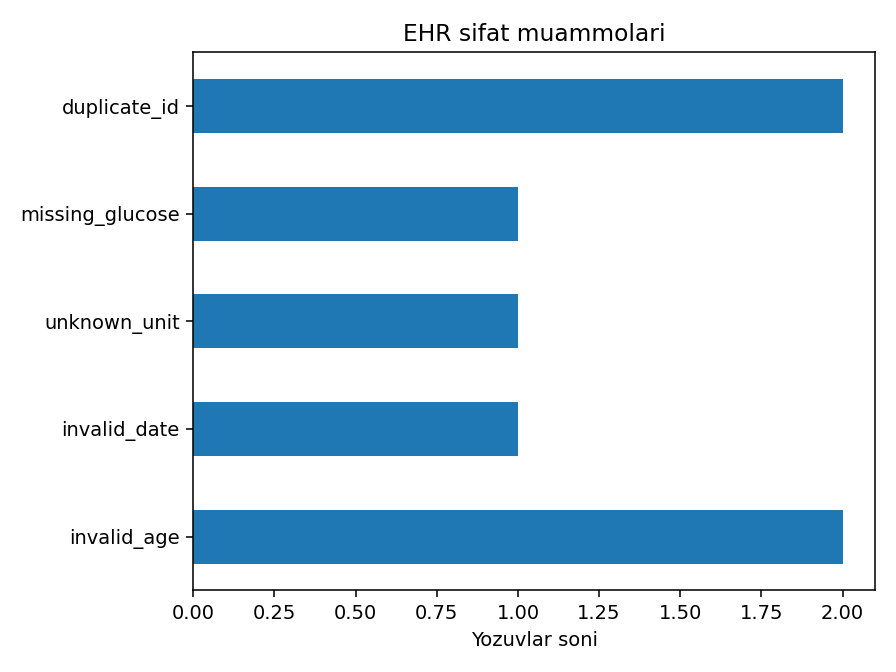

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
